# Decisão entre os encodings

In [1]:
import os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').exists())
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import display
from quantum.encoding import decision

R = Path('reports/a2_encoding')                       # entradas
OUT = Path(os.environ.get('A2_OUT', R)); OUT.mkdir(parents=True, exist_ok=True)   # saídas
PINK, PURPLE = '#FF69B4', '#8A00C4'
CMAP = LinearSegmentedColormap.from_list('pp_auc', ['#FFE4F1', PINK, PURPLE])
pd.set_option('display.width', 250, 'display.max_columns', 40, 'display.max_colwidth', 50)
print('critérios:', dict(probe_margin=decision.PROBE_MARGIN, shot_drop_max=decision.SHOT_DROP_MAX,
                         fidelity_min=decision.FIDELITY_MIN, finalistas=decision.N_FINALISTS,
                         empate_casas=decision.TIE_DECIMALS))

critérios: {'probe_margin': 0.02, 'shot_drop_max': 0.02, 'fidelity_min': 0.85, 'finalistas': 2, 'empate_casas': 2}


In [2]:
ideal = pd.read_csv(R / 'eval_grid.csv')
base = pd.read_csv(R / 'eval_grid_baselines.csv')
shots = pd.read_csv(R / 'noise_shots.csv')
fid = pd.read_csv(R / 'noise_fidelity.csv')
print(len(ideal), 'linhas ideais |', len(base), 'baselines |', len(shots), 'shots |', len(fid), 'fidelidades')
print('pontos:', ideal.point.nunique(), '| leitores:', sorted(ideal.reader.unique()))

306 linhas ideais | 180 baselines | 306 shots | 9 fidelidades
pontos: 17 | leitores: ['kernel', 'measure']


## Ranking


In [3]:
ranking = decision.build_ranking(ideal, base, shots, fid)
ranking.to_csv(OUT / 'decision_ranking.csv', index=False)
cols = ['rank', 'point', 'best_reader', 'val_auc', 'val_probe', 'shot_drop', 'fidelity',
        'depth', 'cx', 'qubits', 'ok_probe', 'ok_shots', 'ok_fidelity', 'eligible']
display(ranking[cols].round(3))

,rank,point,best_reader,val_auc,val_probe,shot_drop,fidelity,depth,cx,qubits,ok_probe,ok_shots,ok_fidelity,eligible
0,1,penultimate/angle/k4,kernel,0.820,0.820,-0.002,0.998,1,0,4,True,True,True,True
1,2,penultimate/angle/k8,measure,0.819,0.822,-0.005,0.996,1,0,8,True,True,True,True
2,3,penultimate/dense/k8,measure,0.819,0.822,0.003,0.996,2,0,4,True,True,True,True
3,4,penultimate/dense/k16,kernel,0.821,0.823,0.003,0.992,2,0,8,True,True,True,True
4,5,feature_maps/dense/k16,kernel,0.820,0.775,0.012,0.992,2,0,8,True,True,True,True
5,6,feature_maps/angle/k8,kernel,0.800,0.778,0.007,0.996,1,0,8,True,True,True,True
6,7,feature_maps/dense/k8,kernel,0.787,0.778,0.005,0.996,2,0,4,True,True,True,True
7,8,feature_maps/angle/k4,kernel,0.748,0.722,0.008,0.998,1,0,4,True,True,True,True
8,9,penultimate/zz_r1_linear/k8,kernel,0.797,0.822,-0.001,0.883,23,14,8,False,True,True,False
9,10,penultimate/zz_r2_circular/k8,kernel,0.786,0.822,0.001,0.746,52,32,8,False,True,False,False


## Funil de elegibilidade

In [4]:
n = len(ranking)
funil = pd.Series({
    'pontos na grade': n,
    'passam critério 1 (sonda linear)': int(ranking.ok_probe.sum()),
    'passam critério 2a (shots)': int(ranking.ok_shots.sum()),
    'passam critério 2b (fidelidade)': int(ranking.ok_fidelity.sum()),
    'elegíveis (1 ∧ 2a ∧ 2b)': int(ranking.eligible.sum()),
})
display(funil.to_frame('n'))
excl = ranking[~ranking.eligible][['point', 'ok_probe', 'ok_shots', 'ok_fidelity']]
print('Excluídos e o motivo (False = reprovou):')
display(excl)

,n
pontos na grade,17
passam critério 1 (sonda linear),8
passam critério 2a (shots),16
passam critério 2b (fidelidade),14
elegíveis (1 ∧ 2a ∧ 2b),8


Excluídos e o motivo (False = reprovou):


,point,ok_probe,ok_shots,ok_fidelity
8,penultimate/zz_r1_linear/k8,False,True,True
9,penultimate/zz_r2_circular/k8,False,True,False
10,penultimate/zz_r1_linear/k4,False,True,True
11,penultimate/zz_r2_circular/k4,False,True,True
12,penultimate/amplitude/k84,False,False,False
13,feature_maps/zz_r1_linear/k8,False,True,True
14,feature_maps/zz_r1_linear/k4,False,True,True
15,feature_maps/zz_r2_circular/k8,False,True,False
16,feature_maps/zz_r2_circular/k4,False,True,True


## 4. Custo do circuito × AUC de validação

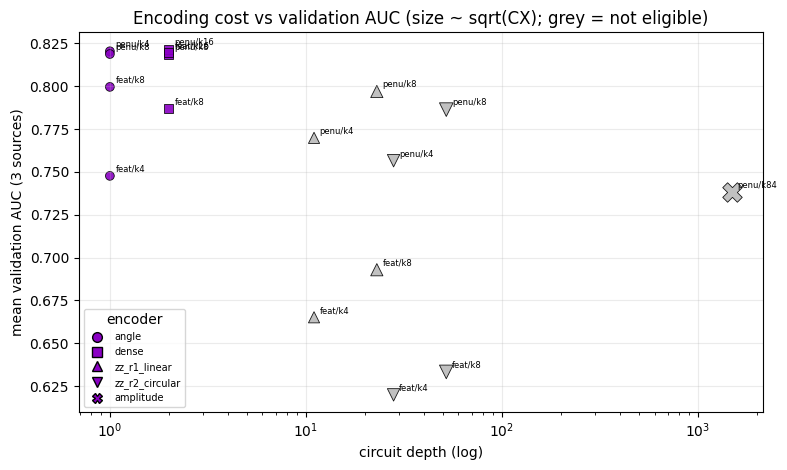

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4.8))
marks = {'angle': 'o', 'dense': 's', 'zz_r1_linear': '^', 'zz_r2_circular': 'v', 'amplitude': 'X'}
for enc, g in ranking.groupby('encoder'):
    ax.scatter(g.depth, g.val_auc, s=40 + 10 * np.sqrt(g.cx), marker=marks.get(enc, 'o'), # type: ignore
               c=np.where(g.eligible, PURPLE, '#BBBBBB'), edgecolor='k', linewidth=.6, label=enc, alpha=.9)
for r in ranking.itertuples():
    ax.annotate(f'{r.layer[:4]}/k{r.k}', (r.depth, r.val_auc), fontsize=6, xytext=(4, 3), textcoords='offset points')# type: ignore
ax.set_xscale('log'); ax.set_xlabel('circuit depth (log)'); ax.set_ylabel('mean validation AUC (3 sources)')
ax.set_title('Encoding cost vs validation AUC (size ~ sqrt(CX); grey = not eligible)')
from matplotlib.lines import Line2D
ax.legend([Line2D([], [], marker=m, ls='', color=PURPLE, markeredgecolor='k', markersize=7) for m in marks.values()],
          list(marks), fontsize=7, title='encoder', loc='lower left'); ax.grid(alpha=.25)
fig.tight_layout(); fig.savefig(OUT / 'fig_cost_vs_val.png', dpi=200); plt.show()

## 5. Finalistas
Selecionados **antes** de olhar qualquer número de teste.

In [6]:
finalists = decision.select_finalists(ranking)
decision.save_finalists(finalists, out=OUT)
display(finalists[['rank', 'point', 'best_reader', 'val_auc', 'val_probe', 'shot_drop', 'fidelity', 'depth', 'cx', 'qubits']].round(3))
print('salvo em', OUT / 'finalists.json')

,rank,point,best_reader,val_auc,val_probe,shot_drop,fidelity,depth,cx,qubits
0,1,penultimate/angle/k4,kernel,0.820,0.820,-0.002,0.998,1,0,4
1,2,penultimate/angle/k8,measure,0.819,0.822,-0.005,0.996,1,0,8


salvo em reports\a2_encoding\finalists.json


## Teste

In [7]:
rep = decision.final_test_report(ideal, base, finalists)
rep.to_csv(OUT / 'final_test_report.csv', index=False)
rep['pair'] = rep.source.str[0] + '>' + rep.target.str[0]
tab = rep.pivot_table(index=['kind', 'model'], columns='pair', values='test_auc', sort=False)
tab['mean_9'] = tab.mean(axis=1)
tab['in_domain'] = tab[['s>s', 'm>m', 'b>b']].mean(axis=1)
display(tab.round(3))

pair                                        s>s    s>m    s>b    m>s    m>m    m>b    b>s    b>m    b>b  mean_9  in_domain
kind      model                                                                                                           
quantum   penultimate/angle/k4 [kernel]   0.783  0.633  0.675  0.623  0.716  0.728  0.638  0.643  0.831   0.697      0.777
          penultimate/angle/k8 [measure]  0.768  0.628  0.682  0.635  0.719  0.717  0.632  0.642  0.835   0.695      0.774
baseline  rbf(pc4)                        0.698  0.572  0.656  0.614  0.726  0.726  0.641  0.666  0.832   0.681      0.752
          logreg(pc4)                     0.759  0.663  0.683  0.614  0.725  0.721  0.641  0.666  0.832   0.700      0.772
          rbf(pc8)                        0.783  0.650  0.679  0.629  0.720  0.728  0.637  0.660  0.831   0.702      0.778
          logreg(pc8)                     0.775  0.655  0.687  0.616  0.721  0.722  0.634  0.654  0.830   0.699      0.775
reference head41_mean (penultimate)       0.749  0.642  0.683  0.625  0.719  0.718  0.642  0.658  0.834   0.697      0.767
          lenet_final                     0.780  0.685  0.682  0.644  0.734  0.730  0.637  0.668  0.829   0.710      0.781

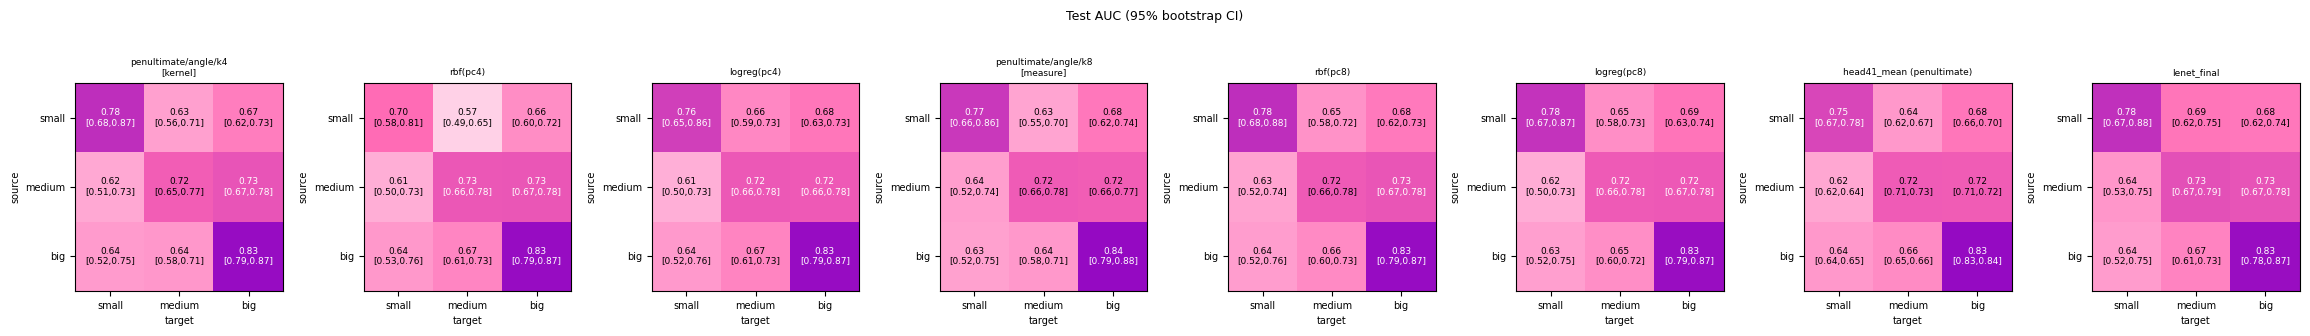

In [19]:
D = ['small', 'medium', 'big']
models = list(dict.fromkeys(rep.model))
fig, axes = plt.subplots(1, len(models), figsize=(2.9 * len(models), 3.4), squeeze=False)
for ax, m in zip(axes[0], models):
    g = rep[rep.model == m]
    A = g.pivot(index='source', columns='target', values='test_auc').loc[D, D]
    lo = g.pivot(index='source', columns='target', values='ci_low').loc[D, D]
    hi = g.pivot(index='source', columns='target', values='ci_high').loc[D, D]
    ax.imshow(A.values, cmap=CMAP, vmin=.55, vmax=.85)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f'{A.values[i, j]:.2f}' + ('' if np.isnan(lo.values[i, j]) else
                    f'\n[{lo.values[i, j]:.2f},{hi.values[i, j]:.2f}]'), ha='center', va='center', fontsize=6.5,
                    color='white' if A.values[i, j] > .72 else 'black')
    ax.set_xticks(range(3), D, fontsize=7); ax.set_yticks(range(3), D, fontsize=7)
    ax.set_xlabel('target', fontsize=7); ax.set_ylabel('source', fontsize=7)
    ax.set_title(m.replace(' [', '\n['), fontsize=6.5)
fig.suptitle('Test AUC (95% bootstrap CI)', fontsize=9); fig.tight_layout()
fig.savefig(OUT / 'fig_final_test_matrices.png', dpi=200); plt.show()

In [20]:
rows = []
for q in rep[rep.kind == 'quantum'].model.unique():
    for b in [m for m in rep[rep.kind == 'baseline'].model.unique()]:
        a = rep[rep.model == q].set_index(['source', 'target']).test_auc
        c = rep[rep.model == b].set_index(['source', 'target']).test_auc
        d = (a - c.groupby(level=[0, 1]).mean()).dropna()
        if len(d) == 9:
            rows.append({'quantum': q, 'baseline': b, 'mean_diff': d.mean(), 'wins': f'{(d > 0).sum()}/9'})
display(pd.DataFrame(rows).round(3))

,quantum,baseline,mean_diff,wins
0,penultimate/angle/k4 [kernel],rbf(pc4),0.016,5/9
1,penultimate/angle/k4 [kernel],logreg(pc4),-0.004,3/9
2,penultimate/angle/k4 [kernel],rbf(pc8),-0.005,2/9
3,penultimate/angle/k4 [kernel],logreg(pc8),-0.003,5/9
4,penultimate/angle/k8 [measure],rbf(pc4),0.014,5/9
5,penultimate/angle/k8 [measure],logreg(pc4),-0.005,3/9
6,penultimate/angle/k8 [measure],rbf(pc8),-0.007,3/9
7,penultimate/angle/k8 [measure],logreg(pc8),-0.004,2/9


## Shots e ruído dos finalistas

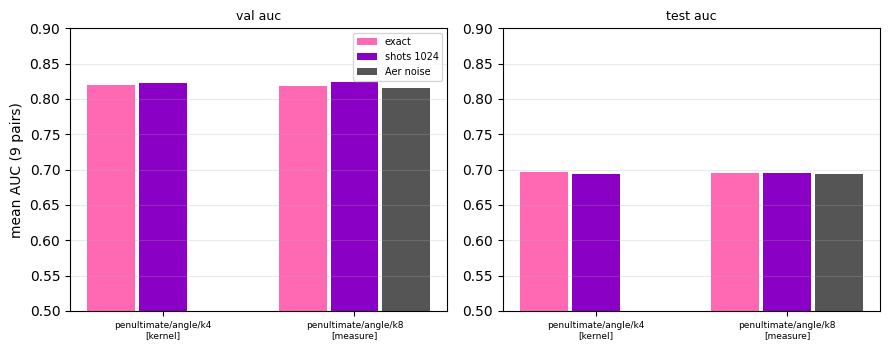

,point,fidelity,fidelity_min,qubits,depth,cx
0,penultimate/angle/k4,0.998,0.998,4,1,0
1,penultimate/angle/k8,0.996,0.996,8,1,0


In [21]:
ns = pd.read_csv(R / 'noise_summary.csv', header=[0, 1], index_col=0)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
for ax, split in zip(axes, ['val_auc', 'test_auc']):
    labels, seen = [], {}
    for i, f in enumerate(finalists.itertuples()):
        rd = f.best_reader
        vals = {'exact': ns.loc[f.point, (split, f'{rd}_exact')], 'shots 1024': ns.loc[f.point, (split, f'{rd}_shots')]}
        if (split, f'{rd}_noise') in ns.columns and not np.isnan(ns.loc[f.point, (split, f'{rd}_noise')]):
            vals['Aer noise'] = ns.loc[f.point, (split, f'{rd}_noise')]
        for j, (k, v) in enumerate(vals.items()):
            ax.bar(i + .27 * (j - 1), v, .25, color=[PINK, PURPLE, '#555555'][j], label=None if k in seen else k); seen[k] = 1
        labels.append(f'{f.point}\n[{rd}]')
    ax.set_xticks(range(len(labels)), labels, fontsize=6.5); ax.set_ylim(.5, .9)
    ax.set_title(split.replace('_', ' '), fontsize=9); ax.grid(axis='y', alpha=.25)
axes[0].legend(fontsize=7); axes[0].set_ylabel('mean AUC (9 pairs)')
fig.tight_layout(); fig.savefig(OUT / 'fig_finalists_noise.png', dpi=200); plt.show()
display(fid[fid.point.isin(finalists.point)].round(3))